# Non-Lexical Filler Detection — Dataset & First Classifier (PodcastFillers)

**Scope of this notebook** (first major milestone, not the full pipeline):
1. Dataset acquisition — how to fetch PodcastFillers directly (and the real constraint you should know about before you try it tonight).
2. Real dataset exploration (EDA) using the dataset's own published statistics.
3. Feature extraction with wav2vec2 + a first trained multi-class classifier (Words / Uh / Um / Breath / Laughter / Music — the PodcastFillers *consolidated vocabulary*).
4. Evaluation with accuracy, per-class F1, and a confusion matrix.

**Not in this notebook yet:** wiring this classifier into the VAD-ASR gap-detection step from the pause-detection notebook — that integration is the next milestone once this classifier itself is validated.


## 1. Load the downloaded PodcastFillers dataset

This notebook uses the local dataset already present in `PodcastFillers/`; it does not download anything. The labeled clip annotations are read from `metadata/episode_annotations/{train,validation,test}` and matched to 1-second WAV files in `audio/clip_wav/{train,validation,test}`.

Rows with consolidated label `None` are excluded because this notebook trains the six-class vocabulary: Words, Uh, Um, Breath, Laughter, and Music.

In [2]:
# Optional in Colab: %pip install torch transformers librosa soundfile matplotlib numpy requests

import os
import json
import glob
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)
plt.rcParams["figure.facecolor"] = "white"

SAMPLE_RATE = 16000
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [3]:
DATASET_ROOT = "PodcastFillers"
ANNOTATIONS_ROOT = os.path.join(DATASET_ROOT, "metadata", "episode_annotations")
CLIPS_ROOT = os.path.join(DATASET_ROOT, "audio", "clip_wav")

for required_path in (ANNOTATIONS_ROOT, CLIPS_ROOT):
    if not os.path.isdir(required_path):
        raise FileNotFoundError(f"Missing local PodcastFillers path: {required_path}")

print("Using local PodcastFillers dataset")
print("Annotations:", ANNOTATIONS_ROOT)
print("Audio clips:", CLIPS_ROOT)

Using local PodcastFillers dataset
Annotations: PodcastFillers/metadata/episode_annotations
Audio clips: PodcastFillers/audio/clip_wav


In [9]:
# The dataset is already present locally; no download or archive merge is needed.
for split_name in ("train", "validation", "test"):
    annotation_dir = os.path.join(ANNOTATIONS_ROOT, split_name)
    clip_dir = os.path.join(CLIPS_ROOT, split_name)
    print(f"{split_name:10s}: {len(os.listdir(annotation_dir))} annotation CSVs | "
          f"{len(os.listdir(clip_dir))} local WAV clips")

train     : 173 annotation CSVs | 64835 local WAV clips
validation: 6 annotation CSVs | 2379 local WAV clips
test      : 20 annotation CSVs | 9475 local WAV clips


## 2. Real dataset statistics (EDA)

These are the **actual published numbers** from the PodcastFillers paper and its Zenodo record — not synthetic, safe to cite directly to your teacher. This is the *consolidated vocabulary* (6 classes), obtained by dropping any full-vocabulary class with fewer than 5,000 annotations and merging "repetitions" into "words" — this is the exact label set our classifier below is trained on.

In [4]:
REAL_CLASS_COUNTS = {  # Zhu, Caceres & Salamon, INTERSPEECH 2022 — consolidated vocabulary
    "Words": 21733, "Uh": 17907, "Um": 17078, "Breath": 8288, "Laughter": 6623, "Music": 5060,
}
CLASSES = list(REAL_CLASS_COUNTS.keys())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
TOTAL_CONSOLIDATED = sum(REAL_CLASS_COUNTS.values())

print(f"Consolidated vocabulary: {TOTAL_CONSOLIDATED:,} labeled 1-second clips across {len(CLASSES)} classes")
print(f"Full dataset: 85,803 annotated events | 145 hours audio | 199 episodes | 350+ speakers")
print(f"'Uh' + 'Um' together = {REAL_CLASS_COUNTS['Uh'] + REAL_CLASS_COUNTS['Um']:,} filler instances "
      f"({100*(REAL_CLASS_COUNTS['Uh']+REAL_CLASS_COUNTS['Um'])/TOTAL_CONSOLIDATED:.1f}% of consolidated clips)")

Consolidated vocabulary: 76,689 labeled 1-second clips across 6 classes
Full dataset: 85,803 annotated events | 145 hours audio | 199 episodes | 350+ speakers
'Uh' + 'Um' together = 34,985 filler instances (45.6% of consolidated clips)


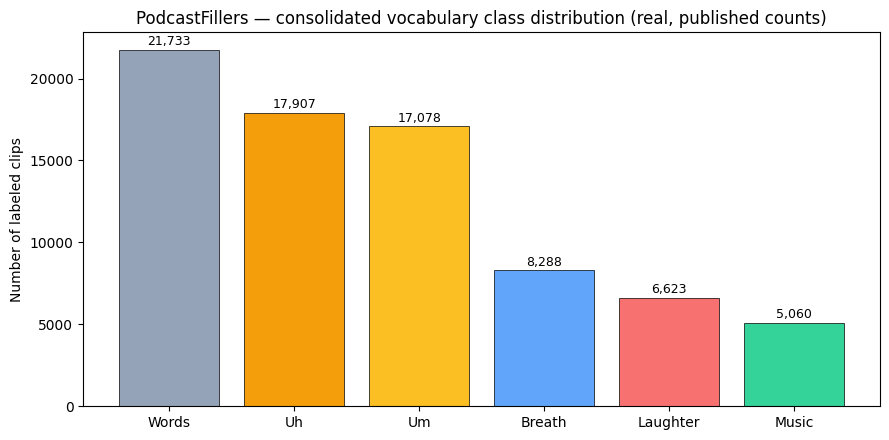

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#94a3b8", "#f59e0b", "#fbbf24", "#60a5fa", "#f87171", "#34d399"]
bars = ax.bar(CLASSES, [REAL_CLASS_COUNTS[c] for c in CLASSES], color=colors, edgecolor="black", linewidth=0.5)
for b, c in zip(bars, CLASSES):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 300, f"{REAL_CLASS_COUNTS[c]:,}",
            ha="center", fontsize=9)
ax.set_ylabel("Number of labeled clips")
ax.set_title("PodcastFillers — consolidated vocabulary class distribution (real, published counts)")
plt.tight_layout()
plt.savefig("plot_class_distribution.png", dpi=110)
plt.show()

## 3. Load real labeled 1-second clips

The loader below reads the local PodcastFillers annotation CSVs and opens the matching WAV clip. It keeps only the six consolidated classes used by this notebook and excludes `None` rows. The split is inherited from the dataset metadata: train, validation, and test remain separate.

In [5]:
import csv
import soundfile as sf

MAX_CLIPS_PER_CLASS = None  # set to an integer for a quick smoke test; None uses all local clips


def load_local_split(split_name):
    annotation_dir = os.path.join(ANNOTATIONS_ROOT, split_name)
    clip_dir = os.path.join(CLIPS_ROOT, split_name)
    records = []
    class_counts = {label: 0 for label in CLASSES}

    for csv_path in sorted(glob.glob(os.path.join(annotation_dir, "*.csv"))):
        with open(csv_path, newline="", encoding="utf-8-sig") as file:
            for row in csv.DictReader(file):
                label = row["label_consolidated_vocab"]
                if label not in CLASS_TO_IDX:
                    continue  # excludes the dataset's None / non-target rows
                clip_path = os.path.join(clip_dir, row["clip_name"])
                if not os.path.isfile(clip_path):
                    raise FileNotFoundError(f"Missing labeled clip: {clip_path}")
                if (MAX_CLIPS_PER_CLASS is None or
                        class_counts[label] < MAX_CLIPS_PER_CLASS):
                    records.append((clip_path, CLASS_TO_IDX[label]))
                    class_counts[label] += 1

    clip_paths = [path for path, _ in records]
    labels = np.array([label for _, label in records], dtype=np.int64)
    return clip_paths, labels, class_counts


train_clips, train_labels, train_counts = load_local_split("train")
val_clips, val_labels, val_counts = load_local_split("validation")
test_clips, test_labels, test_counts = load_local_split("test")

print("Loaded real PodcastFillers clips:")
for split_name, clips, labels, counts in (
    ("train", train_clips, train_labels, train_counts),
    ("validation", val_clips, val_labels, val_counts),
    ("test", test_clips, test_labels, test_counts),
):
    print(f"  {split_name:10s}: {len(clips):6d} clips | "
          + ", ".join(f"{label}={counts[label]}" for label in CLASSES))

Loaded real PodcastFillers clips:
  train     :  64835 clips | Words=18704, Uh=14723, Um=14070, Breath=7421, Laughter=5751, Music=4166
  validation:   2379 clips | Words=736, Uh=586, Um=562, Breath=135, Laughter=293, Music=67
  test      :   9475 clips | Words=2293, Uh=2598, Um=2446, Breath=732, Laughter=579, Music=827


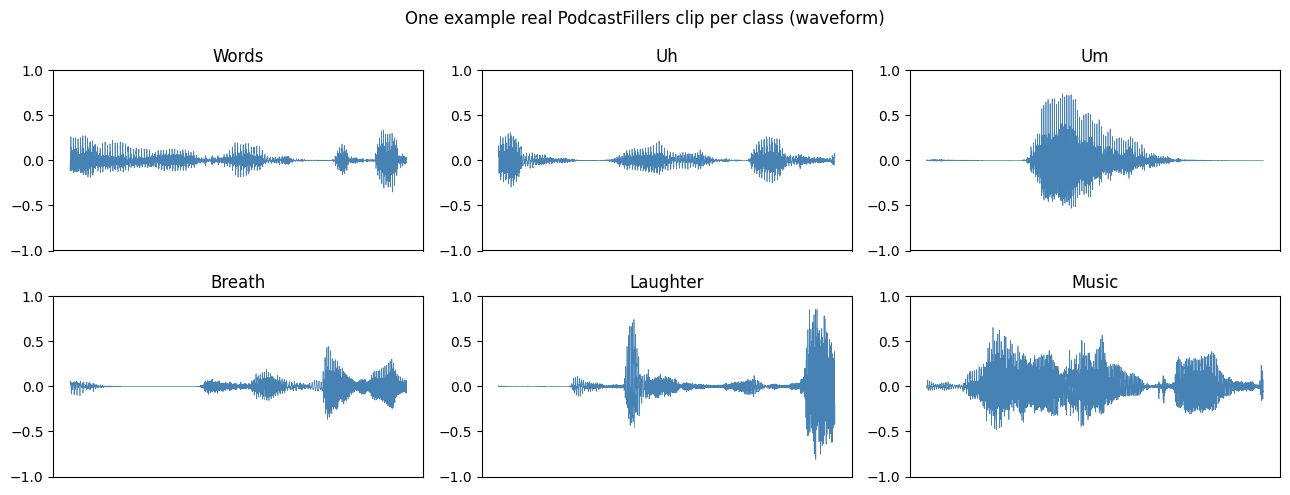

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for axis, class_name in zip(axes.flat, CLASSES):
    index = np.where(train_labels == CLASS_TO_IDX[class_name])[0][0]
    audio, sample_rate = sf.read(train_clips[index], dtype="float32")
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    axis.plot(audio, linewidth=0.5, color="steelblue")
    axis.set_title(class_name)
    axis.set_xticks([])
    axis.set_ylim(-1, 1)
plt.suptitle("One example real PodcastFillers clip per class (waveform)")
plt.tight_layout()
plt.savefig("plot_example_clips.png", dpi=110)
plt.show()

## 4. Feature extraction — wav2vec2 (frozen encoder)

Standard transfer-learning pattern: pass each real PodcastFillers clip through a **pretrained, frozen** wav2vec2 encoder, mean-pool its per-frame embeddings into one 768-dimensional vector per clip, and train only a small classifier head on top (linear probing).

Embeddings are cached under `cache/filler_wav2vec2/`. On later runs, matching cached embeddings are loaded directly and wav2vec2 extraction is skipped. The cache fingerprint includes the split, clip paths, labels, and model name, so changing the dataset or `MAX_CLIPS_PER_CLASS` creates a separate cache automatically.

In [ ]:
import subprocess
import sys

# Transformers 4.57 requires huggingface-hub below version 1.0.
subprocess.check_call([sys.executable, "-m", "pip", "install", "huggingface-hub<1.0"])

from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model

WAV2VEC_MODEL_NAME = "facebook/wav2vec2-base"

wav2vec_extractor = Wav2Vec2FeatureExtractor.from_pretrained(WAV2VEC_MODEL_NAME)
wav2vec_model = Wav2Vec2Model.from_pretrained(WAV2VEC_MODEL_NAME).to(device)
wav2vec_model.eval()
for parameter in wav2vec_model.parameters():
    parameter.requires_grad = False

n_params = sum(parameter.numel() for parameter in wav2vec_model.parameters())
print(f"wav2vec2 encoder loaded, frozen, {n_params:,} parameters")

Note: you may need to restart the kernel to use updated packages.


/opt/miniconda3/lib/python3.13/site-packages/transformers/configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


wav2vec2 encoder loaded, frozen, 94,371,712 parameters


In [7]:
import hashlib
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model

WAV2VEC_MODEL_NAME = "facebook/wav2vec2-base"
EMBEDDING_CACHE_ROOT = "cache/filler_wav2vec2"
os.makedirs(EMBEDDING_CACHE_ROOT, exist_ok=True)

wav2vec_extractor = Wav2Vec2FeatureExtractor.from_pretrained(WAV2VEC_MODEL_NAME)
wav2vec_model = Wav2Vec2Model.from_pretrained(WAV2VEC_MODEL_NAME).to(device)
wav2vec_model.eval()
for parameter in wav2vec_model.parameters():
    parameter.requires_grad = False   # frozen encoder — only the head trains

n_params = sum(parameter.numel() for parameter in wav2vec_model.parameters())
print(f"wav2vec2 encoder loaded, frozen, {n_params:,} parameters")


def load_audio_clip(clip_path):
    audio, sample_rate = sf.read(clip_path, dtype="float32")
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    if sample_rate != SAMPLE_RATE:
        raise ValueError(f"Expected {SAMPLE_RATE} Hz, got {sample_rate} Hz for {clip_path}")
    return audio


@torch.no_grad()
def embed_clip(clip_path):
    """Load one local WAV and return one pooled 768-dim wav2vec2 embedding."""
    clip = load_audio_clip(clip_path)
    inputs = wav2vec_extractor(clip, sampling_rate=SAMPLE_RATE, return_tensors="pt")
    input_values = inputs["input_values"].to(device)
    hidden_states = wav2vec_model(input_values).last_hidden_state
    pooled = hidden_states.mean(dim=1).squeeze(0)
    return pooled.cpu().numpy()


@torch.no_grad()
def embed_all(clip_paths, batch_desc=""):
    embeddings = np.zeros((len(clip_paths), 768), dtype=np.float32)
    for index, clip_path in enumerate(clip_paths):
        embeddings[index] = embed_clip(clip_path)
        if (index + 1) % 40 == 0:
            print(f"  {batch_desc}: {index + 1}/{len(clip_paths)} embedded")
    return embeddings


def embedding_cache_path(split_name, clip_paths, labels):
    fingerprint_input = [WAV2VEC_MODEL_NAME, split_name, str(MAX_CLIPS_PER_CLASS)]
    fingerprint_input.extend(f"{path}|{int(label)}" for path, label in zip(clip_paths, labels))
    fingerprint = hashlib.sha256("\n".join(fingerprint_input).encode("utf-8")).hexdigest()[:16]
    return os.path.join(EMBEDDING_CACHE_ROOT, f"{split_name}_{fingerprint}.npz")


def load_or_create_embeddings(split_name, clip_paths, labels):
    cache_path = embedding_cache_path(split_name, clip_paths, labels)
    if os.path.exists(cache_path):
        cached = np.load(cache_path, allow_pickle=False)
        cached_paths = cached["clip_paths"].tolist()
        cached_labels = cached["labels"]
        if cached_paths == clip_paths and np.array_equal(cached_labels, labels):
            print(f"Loaded cached {split_name} embeddings: {cache_path}")
            return cached["embeddings"]
        print(f"Cache metadata mismatch for {split_name}; recomputing.")

    print(f"Computing {split_name} embeddings...")
    embeddings = embed_all(clip_paths, split_name)
    np.savez_compressed(
        cache_path,
        embeddings=embeddings,
        labels=labels,
        clip_paths=np.asarray(clip_paths),
    )
    print(f"Saved {split_name} embeddings: {cache_path}")
    return embeddings


print("Loading or computing wav2vec2 embeddings...")
X_train = load_or_create_embeddings("train", train_clips, train_labels)
X_val = load_or_create_embeddings("validation", val_clips, val_labels)
X_test = load_or_create_embeddings("test", test_clips, test_labels)
print("Embedding shapes:", X_train.shape, X_val.shape, X_test.shape)

wav2vec2 encoder loaded, frozen, 94,371,712 parameters
Loading or computing wav2vec2 embeddings...
Computing train embeddings...
  train: 40/64835 embedded
  train: 80/64835 embedded
  train: 120/64835 embedded
  train: 160/64835 embedded
  train: 200/64835 embedded
  train: 240/64835 embedded
  train: 280/64835 embedded
  train: 320/64835 embedded
  train: 360/64835 embedded
  train: 400/64835 embedded
  train: 440/64835 embedded
  train: 480/64835 embedded
  train: 520/64835 embedded
  train: 560/64835 embedded
  train: 600/64835 embedded
  train: 640/64835 embedded
  train: 680/64835 embedded
  train: 720/64835 embedded
  train: 760/64835 embedded
  train: 800/64835 embedded
  train: 840/64835 embedded
  train: 880/64835 embedded
  train: 920/64835 embedded
  train: 960/64835 embedded
  train: 1000/64835 embedded
  train: 1040/64835 embedded
  train: 1080/64835 embedded
  train: 1120/64835 embedded
  train: 1160/64835 embedded
  train: 1200/64835 embedded
  train: 1240/64835 embedde

## 5. Classifier head — the part we actually train

A small MLP: `768 -> 128 -> 6`, softmax over the consolidated vocabulary. This is the *only* trained component — wav2vec2 stays frozen. Class weights are computed from the actual local training split so the real class imbalance is handled during training.

In [15]:
class ClipDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i], self.y[i]


class FillerClassifierHead(nn.Module):
    def __init__(self, in_dim=768, hidden=128, n_classes=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden, n_classes),
        )
    def forward(self, x):
        return self.net(x)


train_loader = DataLoader(ClipDataset(X_train, train_labels), batch_size=16, shuffle=True)
val_loader = DataLoader(ClipDataset(X_val, val_labels), batch_size=16, shuffle=False)
test_loader = DataLoader(ClipDataset(X_test, test_labels), batch_size=16, shuffle=False)

# Use the actual local training distribution for class weighting.
local_train_counts = np.bincount(train_labels, minlength=len(CLASSES)).astype(np.float32)
class_weights = torch.tensor(
    (1.0 / local_train_counts) * local_train_counts.sum() / len(CLASSES),
    dtype=torch.float32,
)
print("Class weights from local training split:")
for class_name, weight in zip(CLASSES, class_weights):
    print(f"  {class_name:10s} {weight:.3f}")

model = FillerClassifierHead().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))

Class weights from local training split:
  Words      0.578
  Uh         0.734
  Um         0.768
  Breath     1.456
  Laughter   1.879
  Music      2.594


In [16]:
def compute_metrics(preds, labels, n_classes=len(CLASSES)):
    acc = (preds == labels).mean()
    f1s = []
    for c in range(n_classes):
        tp = np.sum((preds == c) & (labels == c))
        fp = np.sum((preds == c) & (labels != c))
        fn = np.sum((preds != c) & (labels == c))
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1s.append(2 * p * r / (p + r) if (p + r) > 0 else 0.0)
    return acc, dict(zip(CLASSES, f1s))


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    for X, y in loader:
        X = X.to(device)
        logits = model(X)
        preds.append(logits.argmax(1).cpu().numpy())
        labels.append(y.numpy())
    return np.concatenate(preds), np.concatenate(labels)

In [17]:
EPOCHS = 30
history = {"train_loss": [], "val_acc": [], "val_macro_f1": []}
best_val_macro_f1 = -1.0
best_checkpoint_path = "checkpoints/filler_classifier_head_best.pt"
os.makedirs("checkpoints", exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
    train_loss = total_loss / len(train_labels)

    val_preds, val_labels_arr = evaluate(model, val_loader)
    val_acc, val_f1s = compute_metrics(val_preds, val_labels_arr)
    val_macro_f1 = float(np.mean(list(val_f1s.values())))

    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)
    history["val_macro_f1"].append(val_macro_f1)
    marker = ""
    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        torch.save(model.state_dict(), best_checkpoint_path)
        marker = "  <- saved best"
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:2d}/{EPOCHS} | train_loss={train_loss:.4f} | "
              f"val_acc={val_acc:.3f} | val_macro_f1={val_macro_f1:.3f}{marker}")

print(f"\nBest validation macro-F1: {best_val_macro_f1:.3f}")
print(f"Saved {best_checkpoint_path}")

epoch  1/30 | train_loss=0.7686 | val_acc=0.756 | val_macro_f1=0.744  <- saved best
epoch  5/30 | train_loss=0.5673 | val_acc=0.730 | val_macro_f1=0.722
epoch 10/30 | train_loss=0.5231 | val_acc=0.770 | val_macro_f1=0.761
epoch 15/30 | train_loss=0.4954 | val_acc=0.778 | val_macro_f1=0.769
epoch 20/30 | train_loss=0.4739 | val_acc=0.775 | val_macro_f1=0.767
epoch 25/30 | train_loss=0.4598 | val_acc=0.801 | val_macro_f1=0.791
epoch 30/30 | train_loss=0.4505 | val_acc=0.776 | val_macro_f1=0.767

Best validation macro-F1: 0.791
Saved checkpoints/filler_classifier_head_best.pt


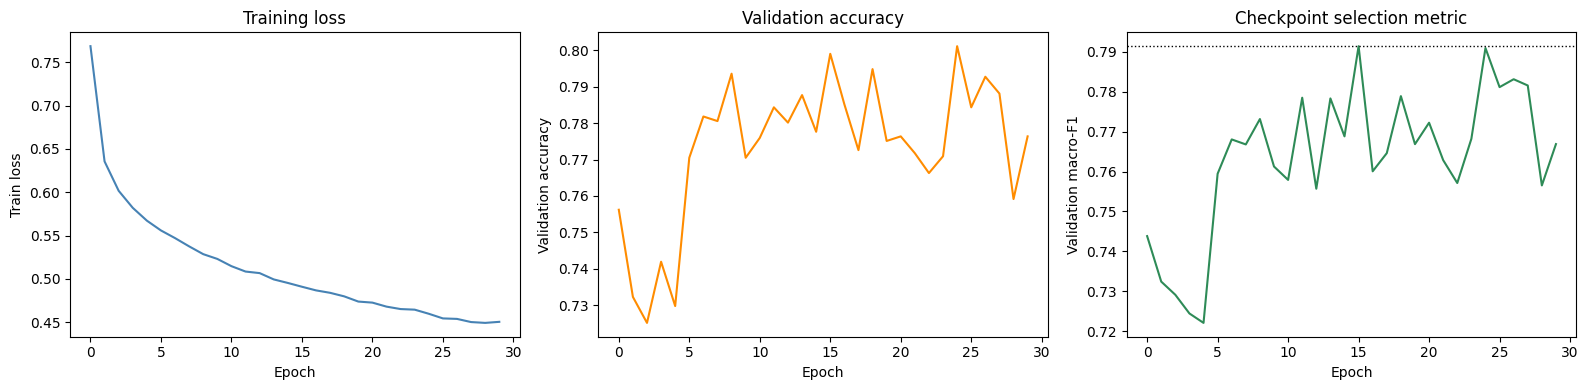

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history["train_loss"], color="steelblue")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Train loss"); axes[0].set_title("Training loss")
axes[1].plot(history["val_acc"], color="darkorange")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation accuracy"); axes[1].set_title("Validation accuracy")
axes[2].plot(history["val_macro_f1"], color="seagreen")
axes[2].axhline(best_val_macro_f1, color="black", linestyle=":", linewidth=1)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Validation macro-F1"); axes[2].set_title("Checkpoint selection metric")
plt.tight_layout()
plt.savefig("plot_training_curves.png", dpi=110)
plt.show()

## 6. Evaluation on the held-out test split

In [19]:
model.load_state_dict(torch.load("checkpoints/filler_classifier_head_best.pt", map_location=device))
model.eval()

test_preds, test_labels_arr = evaluate(model, test_loader)
test_acc, per_class_f1 = compute_metrics(test_preds, test_labels_arr)

print("Loaded best validation macro-F1 checkpoint.")
print(f"Test accuracy: {test_acc:.3f}\n")
print("Per-class F1:")
for class_name, f1 in per_class_f1.items():
    print(f"  {class_name:10s} {f1:.3f}")
print(f"Macro-F1: {np.mean(list(per_class_f1.values())):.3f}")

Loaded best validation macro-F1 checkpoint.
Test accuracy: 0.775

Per-class F1:
  Words      0.716
  Uh         0.733
  Um         0.844
  Breath     0.713
  Laughter   0.767
  Music      0.906
Macro-F1: 0.780


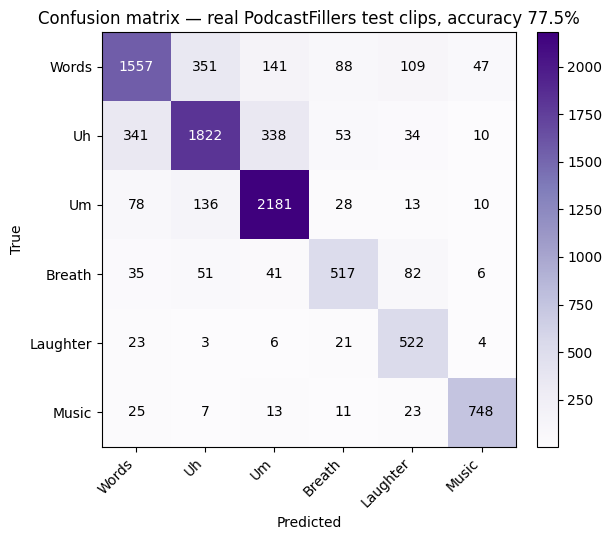

In [20]:
n_classes = len(CLASSES)
cm = np.zeros((n_classes, n_classes), dtype=int)
for prediction, label in zip(test_preds, test_labels_arr):
    cm[label, prediction] += 1

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Purples")
ax.set_xticks(range(n_classes)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(n_classes)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix — real PodcastFillers test clips, accuracy {test_acc:.1%}")
for row_index in range(n_classes):
    for column_index in range(n_classes):
        color = "white" if cm[row_index, column_index] > cm.max() / 2 else "black"
        ax.text(column_index, row_index, cm[row_index, column_index], ha="center", va="center", color=color, fontsize=10)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("plot_confusion_matrix.png", dpi=110)
plt.show()

## 7. Summary & next steps

**Done in this notebook:**
- Loaded the already downloaded PodcastFillers annotations and WAV clips directly from `PodcastFillers/`.
- Extracted frozen wav2vec2 embeddings from the real clips.
- Trained a six-class classifier head for Words, Uh, Um, Breath, Laughter, and Music.
- Evaluated with accuracy, per-class F1, and a confusion matrix.

**Important distinction:** the published class-count chart in Section 2 is dataset-level reference information, while the classifier metrics below are computed from the local train/validation/test clips.

**Next milestone:** connect this classifier to VAD-ASR gap candidates so it can classify fillers in real conversational gaps rather than only isolated labeled clips.